# Election fingerprints: turnout vs. vote share — Bulgarian presidential election, round 1 (25 Oct 2026)

The Benford notebook asked *“do the numbers look invented?”*. This notebook asks a different question:
**do the stations with unusually high turnout also show unusually high support for one candidate?** That is the classic signature
of **ballot stuffing** and **controlled/bought votes**, which digit tests can't see.

## The methods
| Method | Idea | Reference |
|---|---|---|
| **Election fingerprint** | 2-D histogram of turnout × candidate share per station. Honest elections give one compact blob. Stuffing smears it toward the top-right; “extreme” fraud makes a cluster near 100% turnout / 100% share. | Klimek, Yegorov, Hanel & Thurner, *PNAS* 2012 |
| **Turnout-binned votes** | How a candidate's votes and share change as turnout rises. Stuffing adds a long high-turnout tail for one candidate only. | Shpilkin (Russia 2011–), Kobak et al. 2016 |
| **Integer-percentage test** | Fabricated results are often written to hit round percentages (e.g. turnout exactly 80%). Look for an excess of integer percentages. | Kobak, Shpilkin & Pshenichnikov, *Significance* 2016 |
| **Fraud injection** | Add synthetic fraud to the real data to see what it *would* look like, i.e. how much fraud these methods could detect. | — |

## The big caveat
Turnout and vote share can be correlated for innocent reasons: cities vs. villages, age, education, ethnicity. A
candidate who is strong where people vote more will show a “suspicious” slope. So every pattern below also gets checked
**within the same municipality / same building**, where demographics are much more similar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from load_data import load_votes, load_sections

votes = load_votes()
meta = load_sections()

NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:4]
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

df = meta.join(votes)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
print(df.shape)

(12719, 77)


In [2]:
# ---- chart style ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]          # fixed categorical order, follows candidate rank
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

## 1. Which polling stations can be used
Turnout = voters who signed ÷ (voters on the list + voters added on election day). It only means something where the voter
list is meaningful:
* **Abroad**: there are no pre-made lists (almost everyone is “added”), so turnout is ~100% by construction. Excluded.
* **Mobile boxes, ships**: excluded.
* **Very small stations (< 100 registered)**: mostly hospitals, care homes and prisons with special lists. Excluded.
* **Stations where more than half of the voters were added on the day**: special sections. Excluded.

In [3]:
rules = {
    "abroad": df["abroad"],
    "mobile / ship": (df["mobile"] == 1) | (df["ship"] == 1),
    "< 100 registered": df["registered"] < 100,
    "> 50% added on the day": df["voters_added"] / df["registered"] > 0.5,
}
excluded = pd.Series(False, index=df.index)
rows = {}
for name, mask in rules.items():
    rows[name] = (mask & ~excluded).sum()
    excluded |= mask
base = df[~excluded].copy()
rows["→ stations kept"] = len(base)
pd.Series(rows, name="stations").to_frame()

,stations
abroad,613
mobile / ship,263
< 100 registered,1208
> 50% added on the day,9
→ stations kept,10626


## 2. Turnout distribution

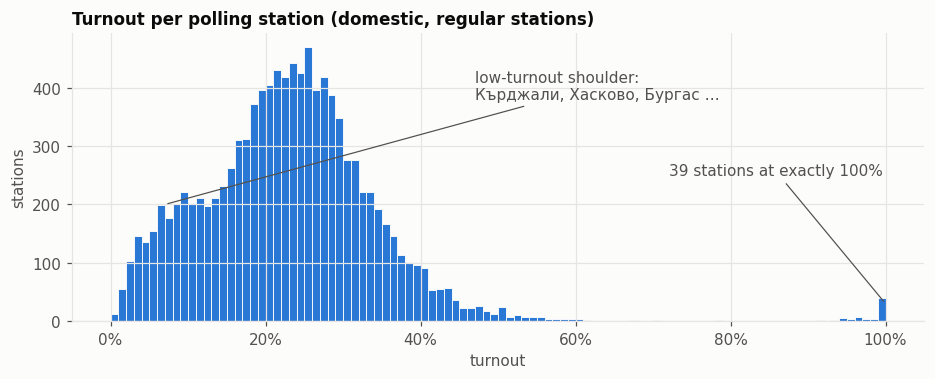

median turnout: 22.9%


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(base["turnout"], bins=np.arange(0, 1.005, 0.01), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlabel("turnout"); ax.set_ylabel("stations"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Turnout per polling station (domestic, regular stations)")
n100 = (base["voted"] >= base["registered"]).sum()
ax.annotate(f"{n100} stations at exactly 100%", xy=(1, 30), xytext=(0.72, 250), color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
low = base[base["turnout"] < 0.12]["admin_name"].value_counts().head(3)
ax.annotate("low-turnout shoulder:\n" + ", ".join(i.split(". ")[1].title() for i in low.index) + " …",
            xy=(0.07, 200), xytext=(0.47, 380), color=INK2, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
plt.show()
print(f"median turnout: {base['turnout'].median():.1%}")

Two features stand out:
* **A low-turnout shoulder (5–12%)**, mostly Кърджали and other regions with a large ethnic-Turkish population and heavy emigration to
  Turkey (emigrants remain on the lists). This is a known demographic effect, not fraud.
* **A spike at exactly 100%.** This is exactly where Klimek's “extreme fraud” would show up, so it needs a closer look.

## 3. The 100%-turnout stations: fraud or paperwork?
If these were stuffed, we would expect (a) a normal-sized voter list with far more voters than the neighbours and (b) one
candidate with an extreme share. We compare each one with the **other polling stations in the same building**, whose voters
come from the same neighbourhood.

In [5]:
def same_address_neighbours(row):
    nb = df[(df["address"] == row["address"]) & (df.index != row.name) & ~df["abroad"] & (df["mobile"] == 0)]
    return pd.Series({
        "neighbours": len(nb),
        "neighbours' median list": nb["voters_list"].median() if len(nb) else np.nan,
        "neighbours' median voted": nb["voted"].median() if len(nb) else np.nan,
        "neighbours' median turnout": nb["turnout"].median() if len(nb) else np.nan,
    })

full = base[base["turnout"] >= 0.95].copy()
full["top candidate"] = full[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
full["top share"] = full[[f"share|{c}" for c in cand_cols]].max(axis=1)
full = full.join(full.apply(same_address_neighbours, axis=1))
cols = ["place", "voters_list", "voters_added", "voted", "turnout", "top candidate", "top share",
        "neighbours", "neighbours' median list", "neighbours' median voted", "neighbours' median turnout"]
full[cols].sort_values("neighbours' median list", ascending=False).style.format({
    "turnout": "{:.0%}", "top share": "{:.0%}", "neighbours' median turnout": "{:.0%}",
    "neighbours' median list": "{:.0f}", "neighbours' median voted": "{:.0f}", "neighbours": "{:.0f}"})

,place,voters_list,voters_added,voted,turnout,top candidate,top share,neighbours,neighbours' median list,neighbours' median voted,neighbours' median turnout
section,,,,,,,,,,,
132900022,с.Ковачево,130,3,133,100%,Илияна Йотова,37%,1,1149,44,4%
211600005,гр.Нова Загора,139,5,139,97%,Андрей Гюров,35%,3,968,8,1%
082800006,гр.Добрич,222,7,222,97%,Илияна Йотова,39%,2,948,269,28%
244607041,гр.София,216,5,221,100%,Андрей Гюров,58%,5,948,381,41%
173300008,гр.Съединение,107,1,108,100%,Илияна Йотова,38%,1,909,87,10%
234609076,гр.София,351,8,359,100%,Андрей Гюров,59%,8,885,328,41%
254613022,гр.София,226,6,226,97%,Андрей Гюров,35%,14,882,236,26%
254613025,гр.София,249,7,249,97%,Андрей Гюров,43%,14,882,230,26%
131900037,гр.Пазарджик,114,8,122,100%,Илияна Йотова,31%,3,869,181,20%


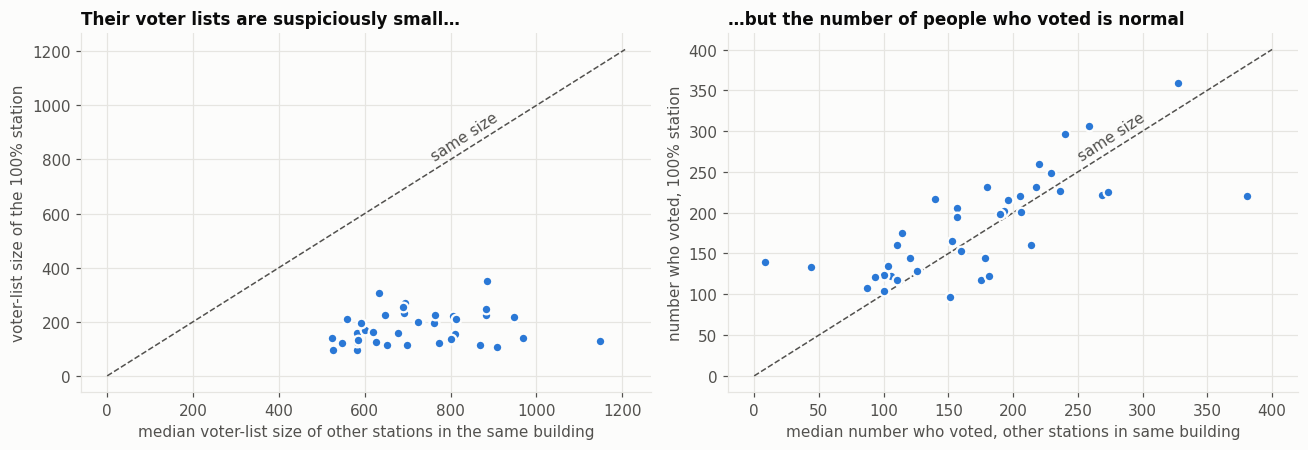

58 stations with turnout ≥ 95%; 39 share a building with other stations.
Median top-candidate share in these stations: 41% (nationwide median of the top candidate per station: 41%)


In [6]:
has_nb = full.dropna(subset=["neighbours' median list"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.scatter(has_nb["neighbours' median list"], has_nb["voters_list"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median list"].max(), has_nb["voters_list"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median voter-list size of other stations in the same building"); ax.set_ylabel("voter-list size of the 100% station")
ax.set_title("Their voter lists are suspiciously small…")
ax = axes[1]
ax.scatter(has_nb["neighbours' median voted"], has_nb["voted"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median voted"].max(), has_nb["voted"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median number who voted, other stations in same building"); ax.set_ylabel("number who voted, 100% station")
ax.set_title("…but the number of people who voted is normal")
fig.tight_layout(); plt.show()

print(f"{len(full)} stations with turnout ≥ 95%; {len(has_nb)} share a building with other stations.")
print(f"Median top-candidate share in these stations: {full['top share'].median():.0%} "
      f"(nationwide median of the top candidate per station: {base[[f'share|{c}' for c in cand_cols]].max(axis=1).median():.0%})")

**Verdict on the 100% spike:** the number of people who voted, and how they voted, look just like the neighbouring stations.
Only the **voter-list size** is wrong: it is 3–5× smaller than in the stations next door and almost equal to the number who
voted. The most likely explanation is a **protocol filling error**: the committee wrote (roughly) the number of voters who
signed into the “voters on the list” field. Ballot stuffing would inflate the *votes*, not shrink the *list*.

That is a data-quality issue worth reporting (the scanned protocols on the CIK results site would confirm it), but it is not a
fraud signal. We **exclude** these stations from the fingerprint so they don't create a fake “100% turnout” cluster.

In [7]:
suspect_list = full.index[full["voters_list"] < 0.6 * full["neighbours' median list"]]
clean = base.drop(index=suspect_list)
print(f"excluded {len(suspect_list)} stations with an implausibly small voter list → {len(clean)} stations remain")

excluded 39 stations with an implausibly small voter list → 10587 stations remain


## 4. The election fingerprint
Each panel is a 2-D histogram: x = station turnout, y = candidate's share in that station, colour = number of stations
(log scale). The grey markers show where the two fraud signatures would appear.

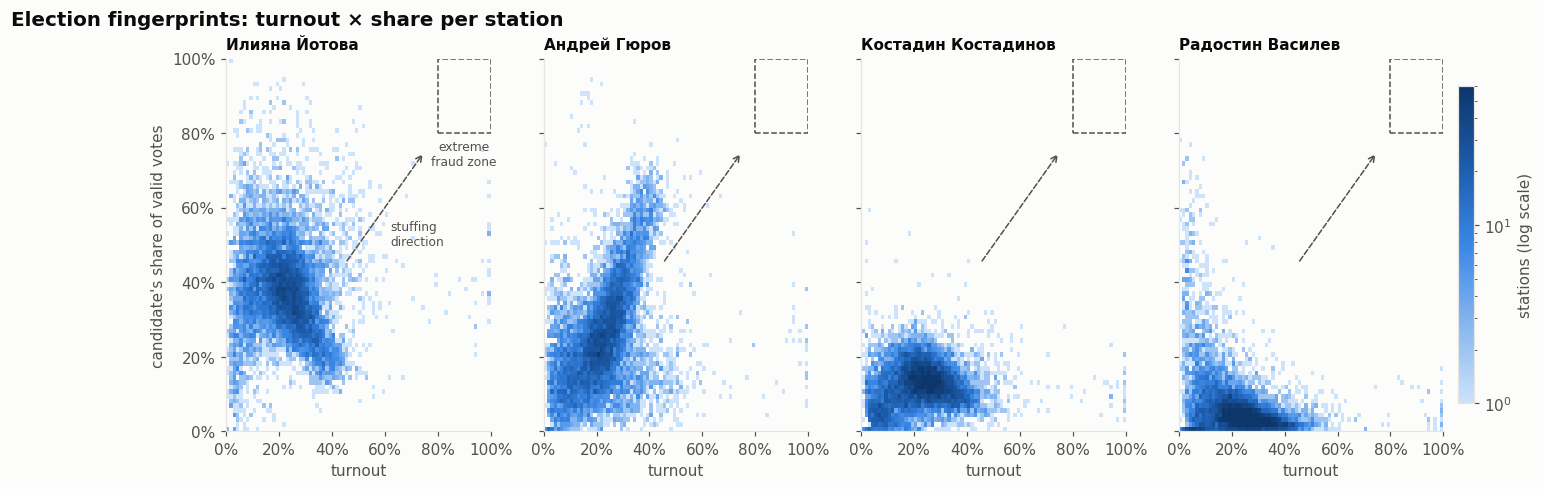

In [8]:
def fingerprint(ax, data, cand, title=None, bins=80, vmax=None):
    h = ax.hist2d(data["turnout"], data[f"share|{cand}"], bins=bins, range=[[0, 1], [0, 1]],
                  cmap=SEQ, norm=LogNorm(vmin=1, vmax=vmax), cmin=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_title(title or short(cand), fontsize=10)
    return h

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
for ax, c in zip(axes, TOP):
    h = fingerprint(ax, clean, c, vmax=60)
    ax.set_xlabel("turnout")
    ax.add_patch(plt.Rectangle((0.8, 0.8), 0.2, 0.2, fill=False, ec=INK2, ls="--", lw=1))
    ax.annotate("", xy=(0.75, 0.75), xytext=(0.45, 0.45), arrowprops=dict(arrowstyle="->", color=INK2, lw=1, ls="--"))
axes[0].set_ylabel("candidate's share of valid votes")
axes[0].text(0.9, 0.78, "extreme\nfraud zone", ha="center", va="top", fontsize=8, color=INK2)
axes[0].text(0.62, 0.5, "stuffing\ndirection", fontsize=8, color=INK2)
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, "Election fingerprints: turnout × share per station")
plt.show()

**What to look for:** an honest election gives one compact blob. Ballot stuffing for candidate X would pull a **comet tail from
the blob toward the top-right** of X's panel, and a cluster inside the dashed box.

What we see: compact blobs, no visible clusters in the extreme-fraud zone. Two candidates show a clear slope: **Гюров's share rises
with turnout, Йотова's falls**. Section 5 checks whether that is fraud or demography.

## 5. Is the slope fraud or demography?
If one candidate's slope came from stuffing, it would persist when we compare **stations in the same municipality** or, even
stricter, **stations in the same building** (same neighbourhood, same committee pool). If it is demography (cities vs.
villages, wealthy vs. poor districts), it should shrink a lot once we compare like with like.

In [9]:
def within_corr(data, cand, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    s = data[f"share|{cand}"] - data.groupby(group)[f"share|{cand}"].transform("mean")
    ok = data.groupby(group)["turnout"].transform("size") >= 2
    return np.corrcoef(t[ok], s[ok])[0, 1]

corr = pd.DataFrame({
    short(c): {
        "raw (whole country)": np.corrcoef(clean["turnout"], clean[f"share|{c}"])[0, 1],
        "within region": within_corr(clean, c, "region"),
        "within municipality": within_corr(clean, c, "municipality"),
        "within same building": within_corr(clean, c, "address"),
    } for c in TOP + [NONE]
}).T
corr.style.format("{:+.2f}").background_gradient(cmap=LinearSegmentedColormap.from_list("d", ["#2a78d6", "#f0efec", "#e34948"]),
                                                vmin=-0.5, vmax=0.5)

,raw (whole country),within region,within municipality,within same building
Илияна Йотова,-0.12,+0.13,+0.15,+0.09
Андрей Гюров,+0.44,+0.25,+0.27,+0.23
Костадин Костадинов,+0.09,+0.08,+0.06,+0.03
Радостин Василев,-0.38,-0.39,-0.40,-0.30
Не подкрепям никого,-0.16,-0.06,-0.04,-0.04


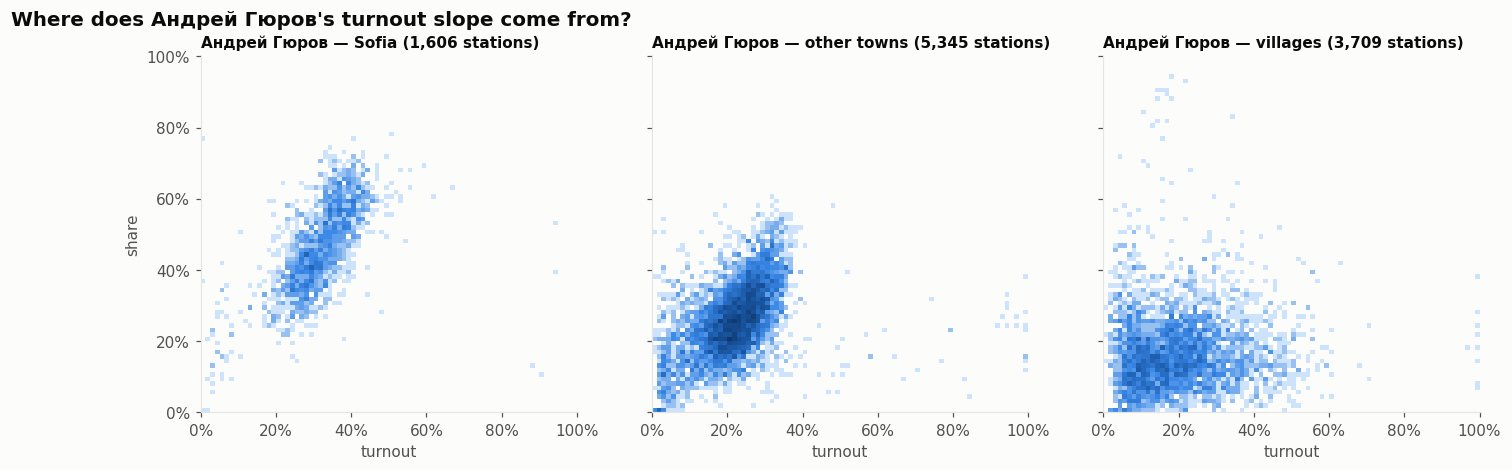

,stations,median_turnout,median share Илияна Йотова,median share Андрей Гюров
type,,,,
Sofia,1606,32%,25%,47%
other towns,5345,22%,37%,26%
villages,3636,18%,44%,15%


In [10]:
# Demography check: Гюров's share vs turnout, cities vs villages
g = ranked[1]
is_city = clean["place"].str.lower().str.startswith("гр.")
sofia = clean["region"].isin([23, 24, 25])
groups = {"Sofia": sofia, "other towns": is_city & ~sofia, "villages": ~is_city}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, mask) in zip(axes, groups.items()):
    h = fingerprint(ax, clean[mask], g, title=f"{short(g)} — {name} ({mask.sum():,} stations)", vmax=40)
    ax.set_xlabel("turnout")
axes[0].set_ylabel("share")
suptitle(fig, f"Where does {short(g)}'s turnout slope come from?")
plt.show()
clean.assign(type=np.select([sofia, is_city], ["Sofia", "other towns"], "villages")).groupby("type").agg(
    stations=("turnout", "size"), median_turnout=("turnout", "median"),
    **{f"median share {short(c)}": (f"share|{c}", "median") for c in TOP[:2]}).style.format(
    {"median_turnout": "{:.0%}", **{f"median share {short(c)}": "{:.0%}" for c in TOP[:2]}})

## 6. Votes by turnout level (Shpilkin's method)
Sort all stations by turnout and add up each candidate's votes per 1-percentage-point turnout bin.
* In a clean election every candidate's curve has roughly the **same bell shape**, and shares stay roughly flat.
* Stuffing creates a **second hump or long right tail** for the beneficiary only, with that candidate's share climbing toward the high-turnout end.

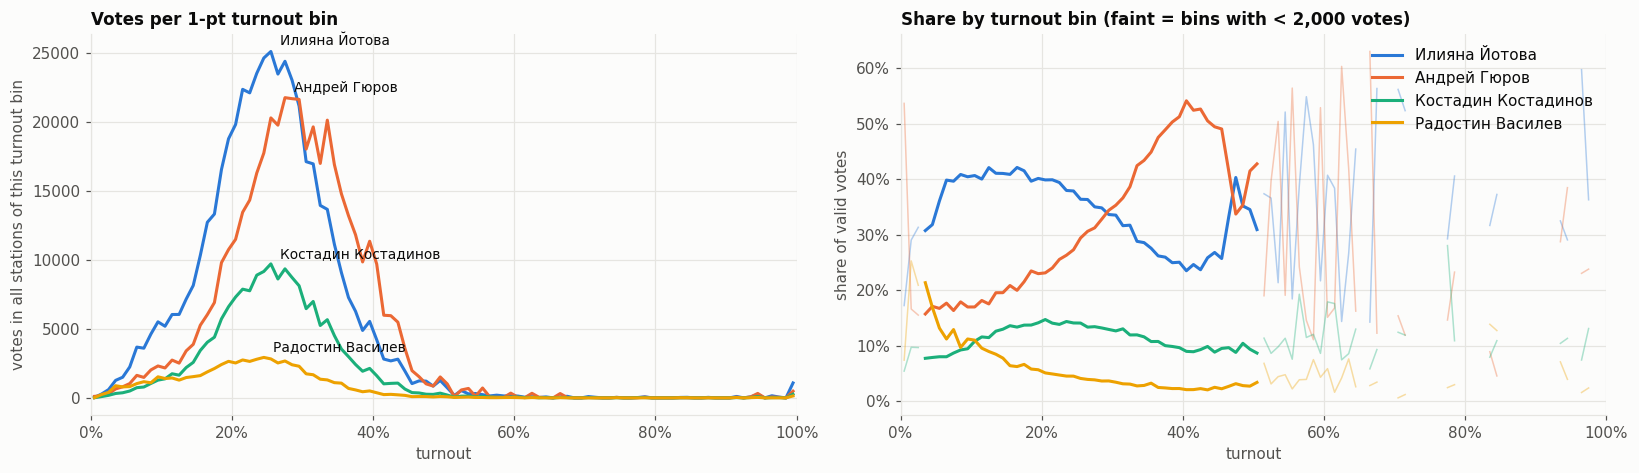

In [11]:
bins = np.arange(0, 1.0001, 0.01)
clean["tbin"] = pd.cut(clean["turnout"], bins, labels=bins[:-1] + 0.005)
by_bin = clean.groupby("tbin", observed=False)[TOP + ["valid"]].sum()
x = by_bin.index.astype(float).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(x, by_bin[c], color=col, lw=2, label=short(c))
ax.set_xlabel("turnout"); ax.set_ylabel("votes in all stations of this turnout bin"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Votes per 1-pt turnout bin"); ax.set_xlim(0, 1)
for c, col in zip(TOP, SERIES):
    i = by_bin[c].values.argmax(); ax.annotate(short(c), (x[i], by_bin[c].iloc[i]), xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)

ax = axes[1]
share = by_bin[TOP].div(by_bin["valid"], axis=0)
enough = (by_bin["valid"] >= 2000).to_numpy()
for c, col in zip(TOP, SERIES):
    y = share[c].to_numpy()
    ax.plot(x, np.where(enough, y, np.nan), color=col, lw=2, label=short(c))
    ax.plot(x, np.where(enough, np.nan, y), color=col, lw=1, alpha=0.35)
ax.set_xlabel("turnout"); ax.set_ylabel("share of valid votes"); ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title("Share by turnout bin (faint = bins with < 2,000 votes)"); ax.set_xlim(0, 1)
ax.legend(loc="upper right")
fig.tight_layout(); plt.show()

**Within-municipality version.** Same idea, but turnout is measured **relative to the municipality's median**. This removes the
city-vs-village effect: a station at +20 pts is one where far more people voted than in comparable stations nearby.

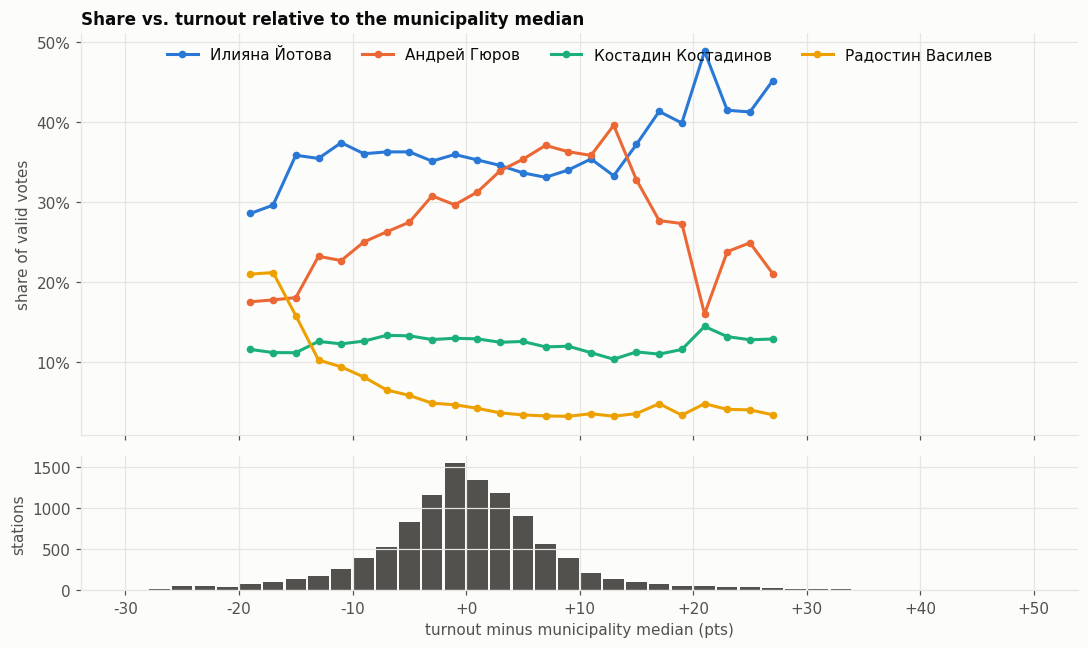

In [12]:
clean["t_rel"] = clean["turnout"] - clean.groupby("municipality")["turnout"].transform("median")
rbins = np.arange(-0.3, 0.51, 0.02)
clean["rbin"] = pd.cut(clean["t_rel"], rbins, labels=rbins[:-1] + 0.01)
rb = clean.groupby("rbin", observed=False)[TOP + ["valid"]].sum()
rshare = rb[TOP].div(rb["valid"], axis=0); xr = rb.index.astype(float).to_numpy(); ok = (rb["valid"] >= 2000).to_numpy()
nstat = clean.groupby("rbin", observed=False).size()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(xr[ok], rshare[c].to_numpy()[ok], color=col, lw=2, marker="o", ms=4, label=short(c))
ax.yaxis.set_major_formatter(pct); ax.set_ylabel("share of valid votes")
ax.legend(ncol=4, loc="upper center"); ax.set_title("Share vs. turnout relative to the municipality median")
axes[1].bar(xr, nstat, width=0.018, color=INK2)
axes[1].set_ylabel("stations"); axes[1].set_xlabel("turnout minus municipality median (pts)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:+.0f}"))
fig.tight_layout(); plt.show()

## 7. What would fraud look like here? (fraud injection)
To calibrate our eyes, and to estimate how much fraud these plots could catch, we take the **real data** and inject
synthetic fraud in favour of the leading candidate (Йотова), following Klimek's model:
* **Incremental fraud** in 5% of stations: a random 10–40% of the people who *didn't* vote are added as ballots for her.
* **Extreme fraud** in 1% of stations: 85–100% of non-voters are added for her and 80% of other candidates' votes are switched to her.

If such fraud had happened, the fingerprint would look like the middle and right panels.

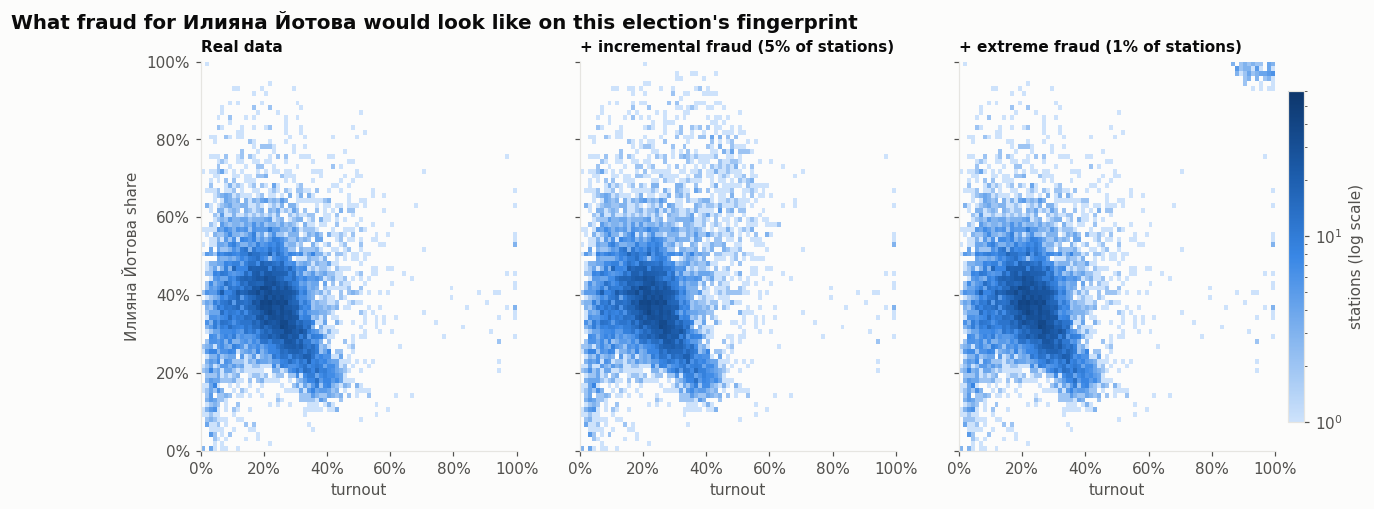

,stations with turnout > 70% and Илияна Йотова > 70%
Real data,2
+ incremental fraud (5% of stations),2
+ extreme fraud (1% of stations),107


In [13]:
rng = np.random.default_rng(7)
W = ranked[0]

def inject(data, cand, frac_stations, stuff_lo, stuff_hi, switch=0.0):
    d = data.copy()
    idx = rng.choice(len(d), int(frac_stations * len(d)), replace=False)
    sub = d.iloc[idx]
    stuffed = np.round((sub["registered"] - sub["voted"]) * rng.uniform(stuff_lo, stuff_hi, len(sub)))
    others = sub["valid"] - sub[cand]
    switched = np.round(others * switch)
    others_cols = [c for c in votes.columns if c != cand]
    keep = 1 - switch
    d.loc[sub.index, others_cols] = np.round(sub[others_cols].mul(keep)).to_numpy()
    d.loc[sub.index, cand] = sub[cand] + stuffed + switched
    d.loc[sub.index, "valid"] = d.loc[sub.index, list(votes.columns)].sum(axis=1)
    d.loc[sub.index, "voted"] = sub["voted"] + stuffed
    d.loc[sub.index, "turnout"] = d.loc[sub.index, "voted"] / sub["registered"]
    for c in votes.columns:
        d.loc[sub.index, f"share|{c}"] = d.loc[sub.index, c] / d.loc[sub.index, "valid"]
    return d

scenarios = {
    "Real data": clean,
    "+ incremental fraud (5% of stations)": inject(clean, W, 0.05, 0.10, 0.40),
    "+ extreme fraud (1% of stations)": inject(clean, W, 0.01, 0.85, 1.0, switch=0.8),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (name, d) in zip(axes, scenarios.items()):
    h = fingerprint(ax, d, W, title=name, vmax=60); ax.set_xlabel("turnout")
axes[0].set_ylabel(f"{short(W)} share")
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, f"What fraud for {short(W)} would look like on this election's fingerprint")
plt.show()

def corner(d, cand, t=0.7, s=0.7):
    return int(((d["turnout"] > t) & (d[f"share|{cand}"] > s)).sum())
pd.DataFrame({name: {f"stations with turnout > 70% and {short(W)} > 70%": corner(d, W)} for name, d in scenarios.items()}).T

## 8. Who gets the extra voters?
Correlation only says turnout and share move together. A sharper question: **when turnout in a station is higher than in
comparable stations, how are the extra ballots split?**

We regress each candidate's votes per registered voter on turnout, comparing stations **within the same municipality** and
**within the same building**. The slope is the share of each additional ballot that goes to the candidate.
* **Honest variation:** extra voters split roughly like everyone else, so slope ≈ the candidate's overall share (ratio ≈ 1).
* **Ballot stuffing for X:** almost every extra ballot goes to X, so X's slope → 1 (ratio → 1 / share, ≈ 2.8 for Йотова), and the
  others' ratios drop.

The last block re-runs the test on the data with the **injected incremental fraud** from section 7, to show what a positive
result looks like.

In [14]:
SLOPE_COLS = TOP + [NONE]

def extra_voter_slopes(data, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    out = {}
    for c in SLOPE_COLS:
        y = data[c] / data["registered"]
        y = y - y.groupby(data[group]).transform("mean")
        out[c] = (t * y).sum() / (t * t).sum()
    return pd.Series(out)

overall_share = clean[SLOPE_COLS].sum() / clean["valid"].sum()
blocks = {}
for label, data in [("real", clean), ("with injected fraud for " + short(W), scenarios["+ incremental fraud (5% of stations)"])]:
    for g, gname in [("municipality", "within municipality"), ("address", "within building")]:
        if label != "real" and g == "address":
            continue
        sl = extra_voter_slopes(data, g)
        blocks[(label, gname, "slope")] = sl
        blocks[(label, gname, "ratio to share")] = sl / overall_share
slope_tab = pd.DataFrame(blocks)
slope_tab.insert(0, "overall share", overall_share)
slope_tab.index = [short(c) for c in slope_tab.index]
slope_tab.style.format("{:.2f}").format("{:.1%}", subset=["overall share"])

## 9. The extreme corner for every candidate
Stations with **turnout > 70% and one candidate > 70%**: the zone where extreme fraud would land. In an honest election a handful
of such stations can occur (e.g. small, very homogeneous villages). Here they are, for inspection.

In [15]:
rows = []
for c in cand_cols:
    m = (clean["turnout"] > 0.7) & (clean[f"share|{c}"] > 0.7)
    for s, r in clean[m].iterrows():
        rows.append({"section": s, "candidate": short(c), "place": r["place"], "address": r["address"][:60],
                     "registered": r["registered"], "voted": r["voted"], "turnout": r["turnout"], "share": r[f"share|{c}"],
                     "municipality median turnout": clean.loc[clean["municipality"] == r["municipality"], "turnout"].median()})
corner_tab = pd.DataFrame(rows)
print(f"{len(corner_tab)} stations in the extreme corner (out of {len(clean):,})")
corner_tab.style.format({"turnout": "{:.0%}", "share": "{:.0%}", "municipality median turnout": "{:.0%}"}) if len(corner_tab) else None

2 stations in the extreme corner (out of 10,587)


,section,candidate,place,address,registered,voted,turnout,share,municipality median turnout
0,042600015,Илияна Йотова,с.Градина,"С.ГРАДИНА, Общинска сграда, столова на Градина 2007 ЕООД,",142,100,70%,71%,17%
1,091600113,Илияна Йотова,с.Звезделина,"С.ЗВЕЗДЕЛИНА, детската градина",123,119,97%,76%,7%


## 10. The reverse pattern: very low turnout, very high share
Stuffing produces high turnout. **Controlled or bought voting** (“контролиран вот”) can look the opposite: in a neighbourhood
where almost nobody votes, a small organised group produces a **low-turnout station dominated by one candidate**. Its tell is a
roughly fixed number of votes that doesn't grow with turnout, which is exactly the negative slope we saw for Василев in section 8.

The table counts stations with **turnout < 12% and one candidate > 50%**.

In [16]:
LOW_T, HIGH_S = 0.12, 0.5
cnt = {}
for c in cand_cols + [NONE]:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)
    if m.sum():
        sub = clean[m]
        cnt[short(c)] = {"stations": int(m.sum()), "votes for candidate there": int(sub[c].sum()),
                         "% of candidate's national votes": sub[c].sum() / clean[c].sum(),
                         "% in towns (гр.)": sub["place"].str.startswith("гр.").mean(),
                         "median registered": sub["registered"].median(), "median voted": sub["voted"].median(),
                         "top regions": ", ".join(f"{r.split('. ')[1].title()} ({n})" for r, n in sub["admin_name"].value_counts().head(4).items())}
pd.DataFrame(cnt).T.style.format({"% of candidate's national votes": "{:.1%}", "% in towns (гр.)": "{:.0%}",
                                  "median registered": "{:.0f}", "median voted": "{:.0f}"})

,stations,votes for candidate there,% of candidate's national votes,% in towns (гр.),median registered,median voted,top regions
Андрей Гюров,15,495,0.1%,20%,606,37,"Кърджали (5), Благоевград (3), Бургас (1), Видин (1)"
Ивайло Симеонов,1,51,0.4%,0%,748,65,Варна (1)
Костадин Костадинов,1,6,0.0%,0%,316,10,Кърджали (1)
Радостин Василев,56,1287,2.0%,77%,854,34,"Пазарджик (15), Стара Загора (9), Пловдив Град (6), Хасково (5)"
Илияна Йотова,327,9474,1.9%,19%,637,45,"Кърджали (73), Хасково (45), Благоевград (29), Шумен (29)"
Не подкрепям никого,2,52,0.1%,0%,755,38,Кърджали (2)


In [17]:
# Where does each candidate win big in low-turnout stations? Regional context: is the whole region low-turnout?
reg = clean.groupby("admin_name").agg(stations=("turnout", "size"), median_turnout=("turnout", "median"))
for c in TOP[:1] + [ranked[3]]:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)
    reg[short(c)] = clean[m].groupby("admin_name").size()
reg = reg.fillna(0).sort_values(short(ranked[3]), ascending=False)
reg.head(12).style.format({"median_turnout": "{:.0%}", short(TOP[0]): "{:.0f}", short(ranked[3]): "{:.0f}"})

,stations,median_turnout,Илияна Йотова,Радостин Василев
admin_name,,,,
13. ПАЗАРДЖИК,341,20%,9,15
27. СТАРА ЗАГОРА,423,24%,6,9
16. ПЛОВДИВ град,469,27%,0,6
29. ХАСКОВО,423,20%,45,5
02. БУРГАС,655,24%,13,4
26. СОФИЯ област,339,24%,1,4
12. МОНТАНА,233,21%,2,3
17. ПЛОВДИВ област,491,20%,12,2
21. СЛИВЕН,279,18%,10,2


In [18]:
V = ranked[3]
sub = clean[(clean["turnout"] < LOW_T) & (clean[f"share|{V}"] > HIGH_S)].copy()
sub["municipality median turnout"] = sub["municipality"].map(clean.groupby("municipality")["turnout"].median())
sub["same-building median turnout"] = sub.apply(
    lambda r: clean.loc[(clean["address"] == r["address"]) & (clean.index != r.name), "turnout"].median(), axis=1)
sub[["place", "address", "registered", "voted", "turnout", V, f"share|{V}", "municipality median turnout", "same-building median turnout"]] \
    .sort_values(f"share|{V}", ascending=False).rename(columns={f"share|{V}": "share"}).style.format(
    {"turnout": "{:.1%}", "share": "{:.0%}", "municipality median turnout": "{:.0%}", "same-building median turnout": "{:.0%}"})

,place,address,registered,voted,turnout,17 Радостин Василев,share,municipality median turnout,same-building median turnout
section,,,,,,,,,
263900033,гр.Самоков,"ГР.САМОКОВ, Обединено училище Неофит Рилски , сграда 2, ул. Христо Максимов №40",819,9,1.1%,7,78%,23%,2%
131900174,с.Мало Конаре,"С.МАЛО КОНАРЕ, ОУ Св. Св. Кирил и Методий , ул. Дванадесета №1",982,38,3.9%,29,76%,21%,13%
262000030,гр.Ихтиман,"ГР.ИХТИМАН, ОУ Св. Св. КИРИЛ И МЕТОДИЙ",1077,38,3.5%,28,74%,21%,nan%
291700011,гр.Любимец,"ГР.ЛЮБИМЕЦ, бул. Одрин №81 Спортна зала Граничар",474,15,3.2%,11,73%,18%,2%
132900028,с.Семчиново,"С.СЕМЧИНОВО, УЛ. ВТОРА №14, ОУ Христо Ботев",917,84,9.2%,61,73%,17%,nan%
273600007,гр.Чирпан,"ГР.ЧИРПАН, ул. Шарампол №26, ОУ Св. св. Кирил и Методий",831,14,1.7%,10,71%,19%,3%
273600006,гр.Чирпан,"ГР.ЧИРПАН, ул. Шарампол №26, ОУ Св. св. Кирил и Методий",660,14,2.1%,10,71%,19%,2%
152400205,с.Буковлък,"С.БУКОВЛЪК, пл. Център №7, ОУ Св. Климент Охридски",1193,58,4.9%,40,69%,23%,9%
272200012,с.Тулово,"С.ТУЛОВО, ул. Роза №40, ОУ Христо Смирненски",419,28,6.7%,19,68%,12%,20%


**Reading this:** two different stories.
* **Йотова's** low-turnout wins sit in regions where turnout was low *everywhere* (Кърджали, Хасково, Шумен, Търговище,
  Силистра). Large parts of those communities simply abstained, and she won among the few who did vote. That is a regional
  pattern, not a station-level anomaly.
* **Василев's** are mostly **town stations with large voter lists** where only 10–80 people voted and most of them for him,
  in municipalities whose median turnout is around 20% (Пазарджик, Стара Загора, Пловдив, Самоков, Чирпан, Любимец…). The other stations
  *in the same building* also have 1–3% turnout, so this is a whole neighbourhood that almost entirely abstained, plus a small
  bloc that voted for one candidate. That is consistent with organised/controlled voting. It is also consistent with a genuinely strong
  local network. **This is a list worth checking against observer reports, not proof.**

## 11. Integer-percentage test (Kobak et al.)
When officials fabricate results to hit a target, the protocol numbers often produce **round percentages**, e.g. turnout
of exactly 60.0% or a candidate share of exactly 50.0%. In Russian elections this showed up as sharp spikes at integer
percentages.

Small stations hit integer percentages by chance (e.g. 50 of 100), so we compare with a **binomial re-sampling null**: each
station's count is re-drawn from Binomial(n, observed rate), which keeps every station's size and rate but removes any
deliberate targeting.

In [19]:
# 0% and 100% are excluded: they are trivially "integer" and dominated by tiny counts
def is_integer_pct(k, n):
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((100 * k) % np.maximum(n, 1) == 0)

def is_round_pct(k, n):     # multiple of 5%
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((20 * k) % np.maximum(n, 1) == 0)

tests = {"Turnout": (clean["voted"], clean["registered"])} | {f"Share {short(c)}": (clean[c], clean["valid"]) for c in TOP}
N_SIM = 200
rows = {}
for name, (k, n) in tests.items():
    k, n = k.to_numpy().astype(int), n.to_numpy().astype(int)
    p = np.clip(k / np.maximum(n, 1), 0, 1)
    obs_i, obs_r = is_integer_pct(k, n).sum(), is_round_pct(k, n).sum()
    sim_i, sim_r = [], []
    for _ in range(N_SIM):
        ks = rng.binomial(n, p)
        sim_i.append(is_integer_pct(ks, n).sum()); sim_r.append(is_round_pct(ks, n).sum())
    sim_i, sim_r = np.array(sim_i), np.array(sim_r)
    rows[name] = {"integer % — observed": obs_i, "integer % — null (5–95%)": f"{np.percentile(sim_i, 5):.0f} – {np.percentile(sim_i, 95):.0f}",
                  "integer % — p": (sim_i >= obs_i).mean(),
                  "multiple of 5% — observed": obs_r, "multiple of 5% — null (5–95%)": f"{np.percentile(sim_r, 5):.0f} – {np.percentile(sim_r, 95):.0f}",
                  "multiple of 5% — p": (sim_r >= obs_r).mean()}
kobak = pd.DataFrame(rows).T
kobak

,integer % — observed,integer % — null (5–95%),integer % — p,multiple of 5% — observed,multiple of 5% — null (5–95%),multiple of 5% — p
Turnout,111,90 – 121,0.31,69,52 – 79,0.4
Share Илияна Йотова,627,571 – 627,0.055,430,384 – 438,0.185
Share Андрей Гюров,525,478 – 527,0.09,327,294 – 345,0.255
Share Костадин Костадинов,413,397 – 445,0.765,223,213 – 258,0.82
Share Радостин Василев,346,303 – 345,0.05,165,139 – 175,0.215


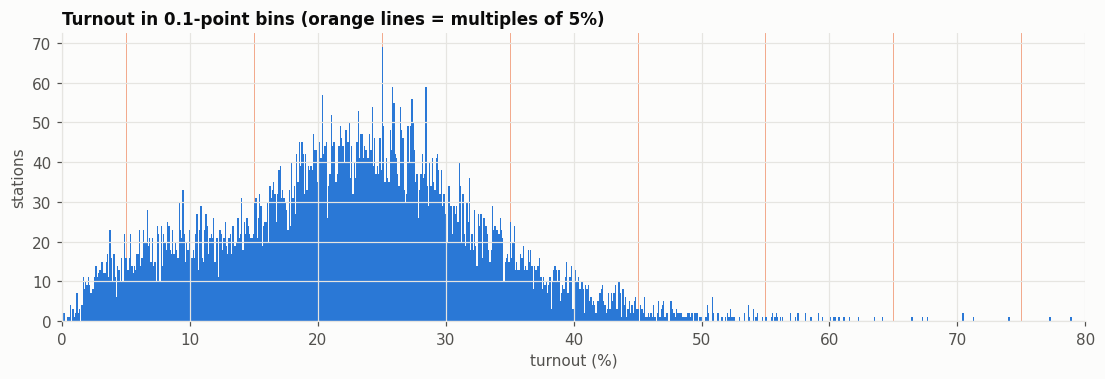

In [20]:
# Visual: fine-grained turnout histogram (0.1-pt bins). Spikes at integer % would appear as regular needles.
fig, ax = plt.subplots(figsize=(12, 3.4))
t = clean["turnout"] * 100
ax.hist(t, bins=np.arange(0, 100.05, 0.1), color=BLUE, linewidth=0)
for k in range(5, 100, 5):
    ax.axvline(k, color=ORANGE, lw=0.6, alpha=0.6, zorder=0)
ax.set_xlim(0, 80); ax.set_xlabel("turnout (%)"); ax.set_ylabel("stations")
ax.set_title("Turnout in 0.1-point bins (orange lines = multiples of 5%)")
plt.show()

## 12. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **100% turnout spike** | 39 stations, all with a voter list 3–5× smaller than the stations in the same building, while votes and shares are normal | **No.** A **protocol filling error** (wrong number in “voters on the list”). A data-quality issue worth reporting. |
| **Fingerprint shape** | Compact blobs; no comet tail toward the top-right for any candidate | **No** |
| **Extreme corner** (turnout & share > 70%) | Only 2 stations, both small villages for Йотова. Injecting extreme fraud in just 1% of stations would put ~105 there. | **No large-scale extreme fraud.** The 2 stations (с. Звезделина: 97% turnout in a municipality with a 7% median; с. Градина) are worth a look. |
| **Гюров's turnout slope** | Driven by Sofia/big cities, where turnout is higher. Within the same building, his extra voters split at 1.17× his share; stuffing for him would give ≈ 3.2×. | **No.** This is demography. |
| **Who gets the extra voters** | Ratios 0.9–1.2 for every major candidate. Injected incremental fraud (5% of stations) raises Йотова's ratio from 1.17 to 1.49. | **No stuffing signature** |
| **Low turnout / high share** | **Василев**: 56 stations (1,287 votes, ~2% of his total), mostly in towns, in neighbourhoods where the whole building has 1–3% turnout. Йотова's 327 such stations come from regions-wide abstention (Кърджали, Хасково, Шумен…). | **Localised pattern consistent with controlled voting for Василев.** Worth checking, not proof. |
| **Integer percentages** | Observed counts are inside or at the edge of the null range; 2 of 10 tests at p ≈ 0.05, which is expected by chance with 10 tests; no needles in the histogram | **No** |

### Bottom line
**There is no sign of large-scale ballot stuffing or fabricated turnout in this election.** The patterns that look suspicious at
first glance (the 100% spike and Гюров's turnout slope) have mundane explanations: a protocol filling error and
city-vs-village demography.

What remains is **localised**: a few dozen low-turnout neighbourhood stations dominated by Василев, plus a handful of individual
stations. Even counting every one of those votes as illegitimate (≈1,300), it would change neither the ranking nor who goes
to the runoff (Йотова leads Гюров by ~43,000 votes; third place is ~295,000 behind).

### Limits of this method
* It detects stuffing that **raises turnout**. Fraud that keeps turnout normal (buying votes from people who would have voted
  anyway, switching votes during counting, intimidation) leaves little trace here.
* Small-scale incremental fraud (< ~1–2% of stations) would be lost in natural variation.
* The analysis excludes abroad, mobile and special sections (≈2,100 stations), where turnout isn't meaningful.

### Possible next steps
* **Paper vs machine votes** in the same building: committees can alter paper counts, but not machine counts.
* **Machine data (`suemg/`) vs protocols:** do the flash-drive results match the published protocols?
* Look up the scanned protocols on the CIK site for the 39 list-error stations, the 2 extreme-corner stations and Василев's 56 stations.